In [53]:
import pandas as pd
import numpy as np

In [54]:
df = pd.read_csv(r"C:\Users\Mozassam Imam\Desktop\AI\CampusX\ML\19_Understanding_data\train_titanic.csv",usecols = ['Age', 'Fare', 'Survived'])

In [55]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [56]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [57]:
df['Age']=df['Age'].fillna(df['Age'].mean())

In [58]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

Train test Split

In [59]:
from sklearn.model_selection import train_test_split

In [60]:
X_train, X_test, y_train,y_test = train_test_split(df.drop(columns=['Survived']),
                                                   df['Survived'],
                                                   test_size = 0.2,
                                                   random_state=42)

In [61]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

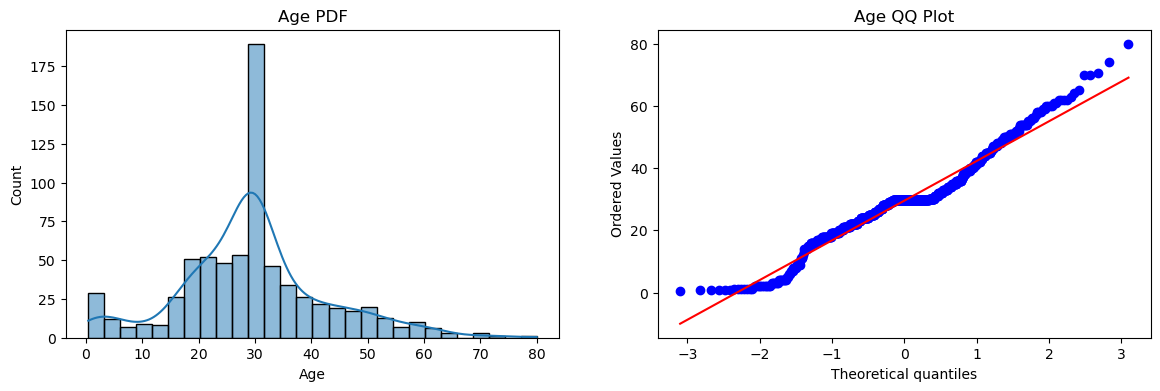

In [62]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Age'],kde = True)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

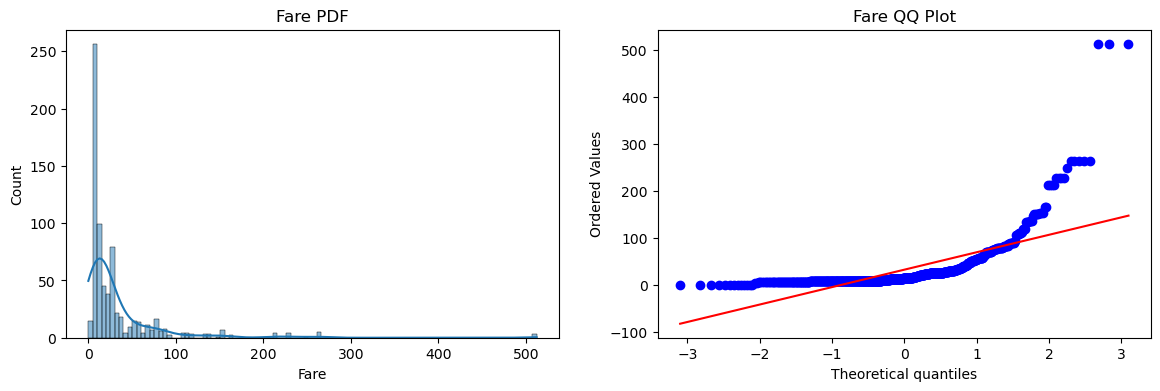

In [71]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Fare'],kde=True)
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [64]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [72]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [78]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)
    
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6759776536312849


Function transformer

In [79]:
from sklearn.preprocessing import FunctionTransformer

In [80]:
trf = FunctionTransformer(func = np.log1p)

In [81]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [82]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6871508379888268


# cross val score

In [83]:
from sklearn.model_selection import cross_val_score

In [86]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [87]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv=10)))

LR 0.678027465667915
DT 0.6633333333333333


In [91]:
from sklearn.compose import ColumnTransformer

In [92]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()
    

Accuracy 0.6589013732833957


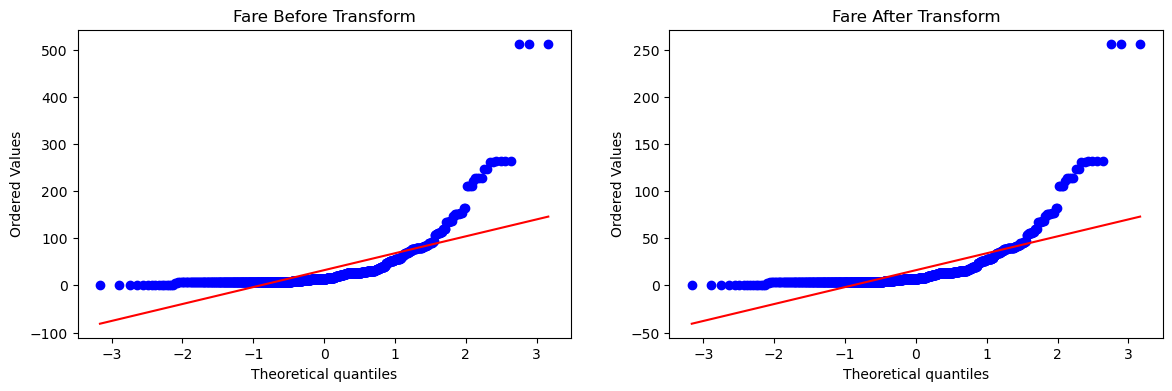

In [96]:
apply_transform(lambda x: x**1/2)